# 01B — TF-IDF + Logistic Regression

Classification baseline for the frozen CONFLICTS split (481 Train / 68 Validation / 72 Test). This notebook is self-contained; no external Python helpers are required. Final Test is disabled by default.

## 1. Setup

In [1]:
from pathlib import Path
import hashlib
import json
import os
import random

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IS_KAGGLE = Path("/kaggle/input").is_dir()
OUTPUT_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load only from the current working directory (no recursive or fallback search).
DATA_DIR = Path.cwd()
required_files = ("conflicts_621.jsonl", "conflicts_original_eval_split.json")
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Missing required files in the current working directory {DATA_DIR}: {missing_files}"
    )

DATA_PATH = DATA_DIR / "conflicts_621.jsonl"
SPLIT_PATH = DATA_DIR / "conflicts_original_eval_split.json"
print("Dataset:", DATA_PATH)
print("Output:", OUTPUT_DIR)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import display

RUN_TEST_EVALUATION = True

Dataset: /Users/GXM/03-trimester 2/AIML339/Assignment/7/conflicts_621.jsonl
Output: /Users/GXM/03-trimester 2/AIML339/Assignment/7


## 2. Dataset and frozen split

Verify the fixed data and split manifest before fitting the baseline.

In [2]:
LABELS = [
    "No conflict",
    "Complementary information",
    "Conflicting opinions and research outcomes",
    "Conflict due to outdated information",
    "Conflict due to misinformation",
]
label2id = {name: i for i, name in enumerate(LABELS)}
id2label = {i: name for name, i in label2id.items()}

with DATA_PATH.open(encoding="utf-8") as f:
    data = [json.loads(line) for line in f if line.strip()]
assert len(data) == 621, f"Expected 621 records, got {len(data)}"

for idx, item in enumerate(data):
    assert set(item) == {"question", "search_results", "conflict_type"}, idx
    assert isinstance(item["question"], str) and item["question"].strip(), idx
    assert item["conflict_type"] in label2id, idx
    assert isinstance(item["search_results"], list) and item["search_results"], idx
    for doc in item["search_results"]:
        assert set(doc) == {"title", "short_text"}, idx
        assert isinstance(doc["title"], str) and isinstance(doc["short_text"], str), idx

expected_counts = [161, 115, 115, 115, 115]
actual_counts = [sum(item["conflict_type"] == label for item in data) for label in LABELS]
assert actual_counts == expected_counts, f"Unexpected class counts: {actual_counts}"

with SPLIT_PATH.open(encoding="utf-8") as f:
    split_manifest = json.load(f)
canonical = "\n".join(json.dumps(x, ensure_ascii=False, sort_keys=True) for x in data)
dataset_sha256 = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
assert dataset_sha256 == split_manifest["dataset_sha256"], "Dataset / manifest mismatch"
assert (split_manifest["original_count"], split_manifest["synthetic_count"]) == (458, 163)
train_ids = split_manifest["train_indices"]
val_ids = split_manifest["validation_indices"]
test_ids = split_manifest["test_indices"]
assert (len(train_ids), len(val_ids), len(test_ids)) == (481, 68, 72)
assert sorted(train_ids + val_ids + test_ids) == list(range(621))
assert all(i < 458 for i in val_ids + test_ids), "Evaluation must use original examples"

rows = [
    {"example_id": i, "question": item["question"],
     "documents": item["search_results"], "label": label2id[item["conflict_type"]]}
    for i, item in enumerate(data)
]
df = pd.DataFrame(rows)
train_df = df.iloc[train_ids].copy().reset_index(drop=True)
val_df = df.iloc[val_ids].copy().reset_index(drop=True)
test_df = df.iloc[test_ids].copy().reset_index(drop=True)
print("Frozen split:", len(train_df), len(val_df), len(test_df))
print("Validation class counts:", val_df.label.value_counts().sort_index().to_dict())

Frozen split: 481 68 72
Validation class counts: {0: 24, 1: 17, 2: 17, 3: 9, 4: 1}


## 3. TF-IDF features and classifier

Use the question and each document’s title and short text. Fit TF-IDF on Train only; use the original balanced Logistic Regression parameters.

In [3]:
def build_example_text(row):
    text = "Question: " + row["question"]
    for i, doc in enumerate(row["documents"], start=1):
        title = doc.get("title", "") or ""
        short_text = doc.get("short_text", "") or ""
        text += f" Document {i}: Title: {title}. Text: {short_text}"
    return text

train_texts = train_df.apply(build_example_text, axis=1).tolist()
val_texts = val_df.apply(build_example_text, axis=1).tolist()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()

vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2))
X_train = vectorizer.fit_transform(train_texts)
X_val = vectorizer.transform(val_texts)

logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
logreg.fit(X_train, y_train)
print("Training complete | train:", X_train.shape, "| validation:", X_val.shape)

Training complete | train: (481, 30000) | validation: (68, 30000)


## 4. Validation and optional final Test

Use fixed five-class and four-class Macro-F1 definitions. Four-class Macro-F1 excludes Misinformation from the average, **not** from the dataset.

Validation: {'n': 68, 'accuracy': 0.5, 'macro_f1_5class': 0.42657807308970097, 'macro_f1_4class': 0.5332225913621262}
Final Test: {'n': 72, 'accuracy': 0.4305555555555556, 'macro_f1_5class': 0.3204101701494469, 'macro_f1_4class': 0.4005127126868086}
                                            precision    recall  f1-score   support

                               No conflict       0.41      0.44      0.42        25
                 Complementary information       0.45      0.28      0.34        18
Conflicting opinions and research outcomes       0.57      0.72      0.63        18
      Conflict due to outdated information       0.20      0.20      0.20        10
            Conflict due to misinformation       0.00      0.00      0.00         1

                                  accuracy                           0.43        72
                                 macro avg       0.33      0.33      0.32        72
                              weighted avg       0.42      0.43      0.42   

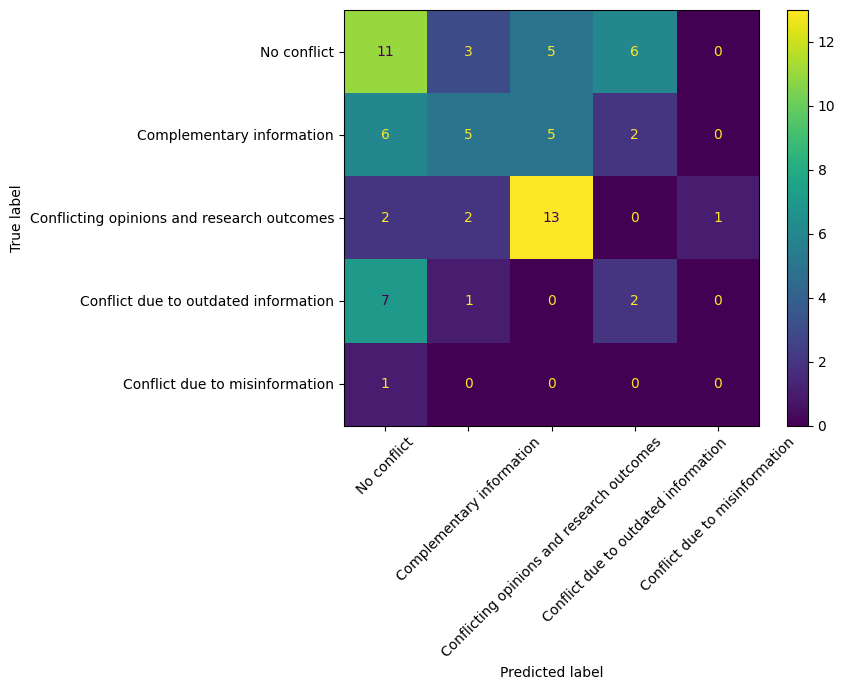

,model,split,n,accuracy,macro_f1_5class,macro_f1_4class
0,TF-IDF + Logistic Regression,validation,68,0.500000,0.426578,0.533223
1,TF-IDF + Logistic Regression,test,72,0.430556,0.320410,0.400513


Saved: /Users/GXM/03-trimester 2/AIML339/Assignment/7/tfidf_logreg_metrics.csv


In [4]:
FOUR_LABELS = LABELS[:4]

def classification_metrics(y_true, y_pred):
    y_true, y_pred = list(y_true), list(y_pred)
    if len(y_true) != len(y_pred) or not y_true:
        raise ValueError("Metrics require equal, non-empty arrays")
    if not set(y_true + y_pred).issubset(LABELS):
        raise ValueError("Unknown category")
    return {
        "n": len(y_true),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1_5class": float(f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)),
        "macro_f1_4class": float(f1_score(y_true, y_pred, labels=FOUR_LABELS, average="macro", zero_division=0)),
    }

def score_predictions(truth_ids, prediction_ids):
    return classification_metrics(
        [LABELS[int(i)] for i in truth_ids],
        [LABELS[int(i)] for i in prediction_ids],
    )

val_pred = logreg.predict(X_val)
val_scores = score_predictions(y_val, val_pred)
rows = [{"model": "TF-IDF + Logistic Regression", "split": "validation", **val_scores}]
print("Validation:", val_scores)

if RUN_TEST_EVALUATION:
    test_texts = test_df.apply(build_example_text, axis=1).tolist()
    X_test = vectorizer.transform(test_texts)
    y_test = test_df["label"].to_numpy()
    test_pred = logreg.predict(X_test)
    test_scores = score_predictions(y_test, test_pred)
    rows.append({"model": "TF-IDF + Logistic Regression", "split": "test", **test_scores})
    print("Final Test:", test_scores)
    print(classification_report(y_test, test_pred, labels=list(range(5)),
                                target_names=LABELS, zero_division=0))
    cm = confusion_matrix(y_test, test_pred, labels=list(range(5)))
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, xticks_rotation=45)
    fig.tight_layout()
    plt.show()

summary = pd.DataFrame(rows)
summary_path = OUTPUT_DIR / "tfidf_logreg_metrics.csv"
summary.to_csv(summary_path, index=False)
display(summary)
print("Saved:", summary_path)